# Supernova multiple source

This tutorial shows how to use the public point-source data for a time dependent point-source analysis with the public IceTracks-DR2 (14-year) release, using the `IC86_I-XI` subset in this example. The time fit is performed by the expectation maximization (EM) algorithm.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as st
import numpy.lib.recfunctions as rf
from io import StringIO
import skyllh
from skyllh.core.source_model import PointLikeSource
from skyllh.core.random import RandomStateService
from skyllh.analyses.i3.publicdata_ps.time_dependent_ps import (
    create_analysis,
    do_trial_with_fixed_time_profile,
    unblind_single_flare_fixed_time_profile,
)
from skyllh.core.config import Config

First we need to create a local configuration for the analysis. We will create just the default configuration:

In [3]:
cfg = Config()

Now we can get the dataset:

In [4]:
datasets = skyllh.create_datasets('IceTracks-DR2', cfg=cfg, names=['IC86_I-XI'])
# can use only one (consistent) "season" 2010 -- 2021; fine for your catalogue iIrc

We create the ``Analysis`` instance for some fake catalogue:

In [14]:
# fake example catalogue;
# - one random where we don't expect anything
# - one matching location and time of the 2014/15 TXS excess
cat = pd.read_csv(StringIO("""name,ra,dec,mjd
A,0.0,60.0,56000.
TXS,77.3581,5.6931,57000.
TXS0,77.3,5.7,57000.
"""), index_col=0) # use name as index column


In [15]:
# common BPL parameters; these would be chosen from the model
bpl_params = {'dt_break': [10, 20], 'alpha': [2,3,4]}

# Set up corresponding analyses, takes about 4m per source
ana = {}
for name, row in cat.iterrows():
    _src = PointLikeSource(
        name=name,
        ra=np.radians(row["ra"]),
        dec=np.radians(row["dec"]),
        classification=None)
    ana[name] = create_analysis(
        cfg=cfg, datasets=datasets,
        source=_src,
        refplflux_gamma=2.0,
        bpl={"t0": row["mjd"]} | bpl_params,
    )

100%|██████████| 44/44 [00:00<00:00, 1780.54it/s]


In [16]:
# unblind, store in a NumPy array
unblind_dt = [
        ('ts', np.float64),
        ('ns_fit', np.float64),
        ('gamma_fit', np.float64),
        # if there are more fit parameters, they'd appear here
    ]
ub = np.empty((cat.index.size,), dtype=unblind_dt)

for i_src, name in enumerate(cat.index):
    _ts, _fit_params = unblind_single_flare_fixed_time_profile(ana=ana[name], bpl=bpl_params | {'t0': cat.loc[name, 'mjd']})
    ub[i_src] = (_ts, *tuple(_fit_params))
# this array can then be used in vectorized operations
# (as long as the source index stays in the same order)

Run background trials, i.e. ``mean_n_sig=0``

In [29]:
outdir = "./output"
cat_names = "_".join(cat.index)
os.makedirs(outdir, exist_ok=True)
bg_trials_path = os.path.join(outdir, f"bg_trials.{cat_names}.npy")

# Set up correlated trials:
seed = 4
n_trial = 400 # 1 minute/(100 trials x sources)
np_rs = np.random.RandomState(seed)
seeds = np_rs.randint(2**32, size=n_trial) # reproducible set of RNG seeds

bg_trials = []

# Instead of do_trials_with_em(ana=ana, n=n_trial, seed=seed, mean_n_sig=0, ncpu=4),
# set up each trial separately to control the seed
for _name, _ana in ana.items():
    print(_name)
    _bg_trials = []
    for i_seed, _s in enumerate(seeds):
        _bg_trials.append(
            do_trial_with_fixed_time_profile(_ana, rss=RandomStateService(seed=_s),
            mean_n_sig=0,
            bpl={'t0':cat.loc[_name, 'mjd']}|bpl_params)
        )
        print(f"[{i_seed + 1:5d} / {seeds.size}]", end="\r")

    print("\n[ Done. ]")
    bg_trials.append(np.concatenate(_bg_trials))
# (I think it's supposed to work otherwise, and then we'd get the benefits of a common progress bar
# and multiprocessing, but currently not seeing that it actually works.)
bg_trials = np.vstack(bg_trials)

# can add previously saved trials if they exist:
if os.path.exists(bg_trials_path):
    bg_trials = np.hstack([np.load(bg_trials_path), bg_trials])

# this then has the expected shape, i.e. no seed collisions
assert bg_trials.shape == (cat.index.size, np.unique(bg_trials['seed']).size)
# and matching seeds across the sources:
assert np.all(bg_trials['seed'][0] == bg_trials['seed'])
# => can combine with unblinded TS to get pre-trial p-values
# => and from there, post-trial p-value.

np.save(bg_trials_path, bg_trials)

A
[  400 / 400]
[ Done. ]
TXS
[  400 / 400]
[ Done. ]
TXS0
[  400 / 400]
[ Done. ]


In [18]:
# can also merge this into the DataFrame
cat = pd.merge(cat, pd.DataFrame(ub, index=cat.index), left_index=True, right_index=True)
cat

,ra,dec,mjd,ts,ns_fit,gamma_fit
name,,,,,,
A,0.0000,60.0000,56000.0,0.145076,4.640677,4.408827
TXS,77.3581,5.6931,57000.0,8.791185,9.438866,2.157884
TXS0,77.3000,5.7000,57000.0,8.491060,8.848324,2.139841


Can make some plots of the TS distribution **per source,** which translates the unblinded TS into a p-value.

A, TS=0.15, p=4.7e-01 = 0.1 sigma
TXS, TS=8.79, p=8.8e-03 = 2.4 sigma
TXS0, TS=8.49, p=1.0e-02 = 2.3 sigma


(1, np.float64(616.4653138123157))

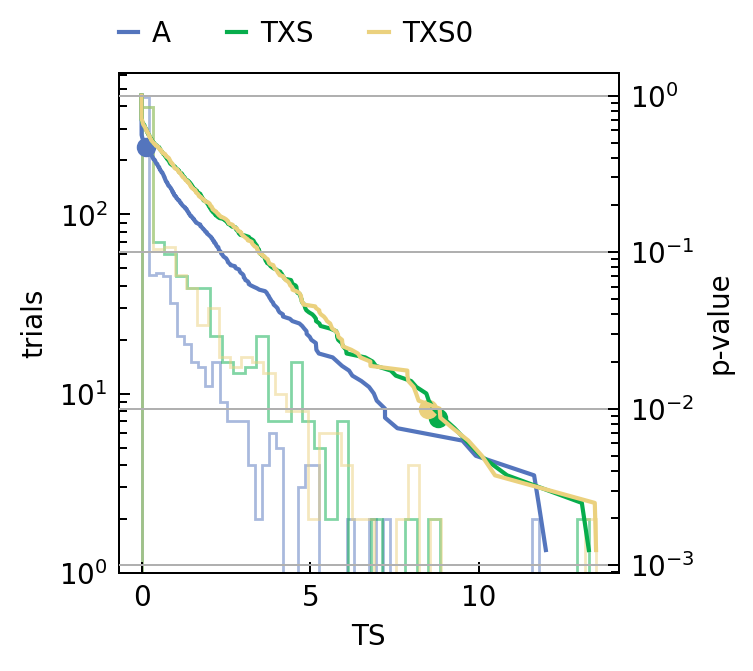

In [ ]:
def plot_sf(ts, ax=None, **kwargs):
    """Plot the survival function from an array of test statistic values

    Args:
        ax (matplotlib Axes, optional): Axes to plot on.
        ts (np.ndarray): Array of TS, defined to increase for more signal-like.
        **kwargs: Forwarded to plot().
    """
    if ax is None:
        ax = plt.gca()
    ax.plot(np.sort(ts), (1 - np.arange(ts.size) / ts.size), **kwargs)

def print_p(_ts, _ts0, name="", print_result=True):
    """Calculate

    Args:
        _ts (float): Unblinded TS value
        _ts0 (np.ndarray): Background TS values
        name (str): Names of source to print.

    Returns:
        float: p-value
    """
    _p = np.count_nonzero(_ts0 >= _ts) / _ts0.size
    _sigma = st.norm.isf(_p)
    if print_result:
        print(f"{name}, TS={_ts:.2f}, p={_p:.1e} = {_sigma:.1f} sigma")
    return _p

ax_n = plt.subplot()
ax_p = ax_n.twinx()

ax_n.set_xlabel("TS")
ax_n.set_ylabel("trials")


ax_n.set_yscale("log")
ax_n.grid(False)

ax_p.set_ylabel("p-value")
ax_p.set_yscale("log")

for i, _bg in enumerate(bg_trials):
    ax_n.hist(_bg['ts'], bins='auto', color=f"C{i+1}", histtype='step', alpha=0.5)
    plot_sf(_bg['ts'], ax=ax_p, color=f"C{i+1}", label=cat.index[i])
    _p = print_p(ub['ts'][i], _bg['ts'], cat.index[i])
    ax_p.scatter(ub[i]['ts'], _p, color=f"C{i+1}")
ax_p.legend(loc=(0,1.05), ncols=4)

ax_n.set_ylim(1, ax_n.get_ylim()[1])


# TXS pre-trial ~1%
# and so is the second near-coincident TXS0

In [38]:
# unblinded p-values
p = np.count_nonzero(bg_trials['ts'] >= ub['ts'][:, np.newaxis], axis=1) / bg_trials.shape[1]
n_sigma = st.norm.isf(p) # positive-defined n-sigma, i.e. 0 sigma = 50%
n_sigma_max = n_sigma.max()
cat["p"] = p
cat["n_sigma"] = n_sigma
cat

,ra,dec,mjd,ts,ns_fit,gamma_fit,p,n_sigma
name,,,,,,,,
A,0.0000,60.0000,56000.0,0.145076,4.640677,4.408827,0.47125,0.072128
TXS,77.3581,5.6931,57000.0,8.791185,9.438866,2.157884,0.00875,2.376031
TXS0,77.3000,5.7000,57000.0,8.491060,8.848324,2.139841,0.01000,2.326348


In [39]:
# Now we insert some new axes to do this p-value calculation for every BG trial per source
ts0 = bg_trials['ts']
p0 = np.count_nonzero(ts0[:, :, np.newaxis] >= ts0[:, np.newaxis, :], axis=1) / ts0.shape[1]

# And then we have a best p-value from unblind
p_min = p.min()
p_min0 = p0.min(axis=0) # 0-th axes are sources

# can translate this into n-sigma as well
n_sigma_max0 = st.norm.isf(p_min0)

most significant, TS=2.38, p=1.9e-02 = 2.1 sigma


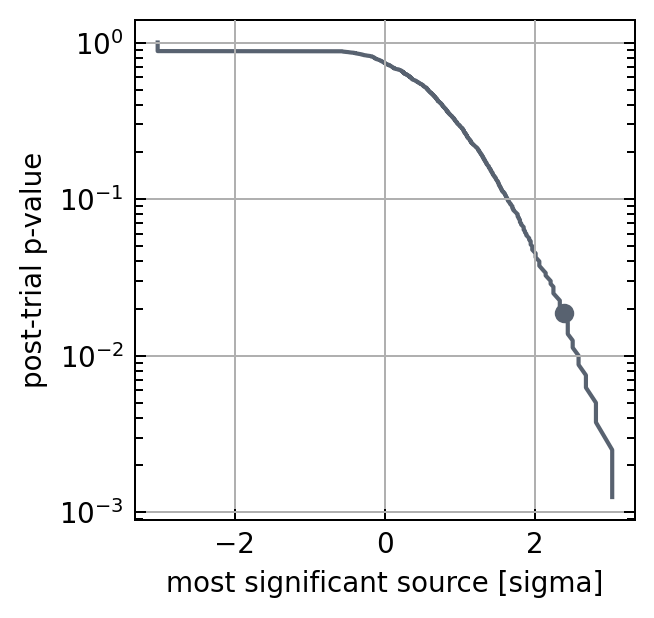

In [40]:
# The same plot as before, now for the best n-sigma of the unblinding and each correlated BG trial.
plt.xlabel("most significant source [sigma]")
plt.ylabel("post-trial p-value")

plot_sf(n_sigma_max0, color="C0")
plt.semilogy()
p_post = print_p(n_sigma_max, n_sigma_max0, "most significant")
plt.scatter(n_sigma_max, p_post, color="C0")
# TXS is 2% post-trial
# which is a trial factor of 2
# (the number of independent sources)
# rather than 3 (the number of entries in the catalogue)